# Advanced Data Mining for Data-Driven Insights and Predictive Modeling
## Deliverable 4: Final Insights, Recommendations, and Consolidated Analysis

**Course:** MSCS-634-M50 — Advanced Big Data and Data Mining  
**Institution:** University of the Cumberlands  
**Authors:** Ranju Khanal & Anusha Sharma  
**Instructor:** Professor Satish Penmatsa  
**Date:** November 2026  

---

### Project Overview
This notebook consolidates the complete analytical workflow across all four deliverables:
1. **Deliverable 1** — Data Collection, Cleaning, and Exploration  
2. **Deliverable 2** — Regression Modeling and Performance Evaluation  
3. **Deliverable 3** — Classification, Clustering, and Association Rule Mining  
4. **Deliverable 4** — Final Insights, Recommendations, Ethical Considerations, and Synthesis  

**Dataset:** Breast Cancer Wisconsin (Diagnostic) — 569 records, 10 selected mean morphological measurements + diagnosis label.  
Source: UCI Machine Learning Repository / scikit-learn.

> **Ethics Note:** This is a retrospective teaching dataset. All findings are exploratory and must not be interpreted as clinical diagnostic rules or causal claims.

In [2]:
# ============================================================
# 0. Global Imports and Configuration
# ============================================================
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
                                     cross_val_score, GridSearchCV, learning_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, silhouette_score)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

OUT = Path("figures")
DATA = Path("data")
OUT.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)

print("Environment ready. Pandas version:", pd.__version__)

Environment ready. Pandas version: 2.3.3


---
# Deliverable 1: Data Collection, Cleaning, and Exploration

**Objective:** Load the dataset, select 10 interpretable mean measurements, audit data quality, perform exploratory data analysis, and establish a reproducible foundation for later modeling. No predictive models are trained in this stage.

In [4]:
# ============================================================
# D1.1 — Load and select features
# ============================================================
SELECTED = [
    "mean radius", "mean texture", "mean perimeter", "mean area",
    "mean smoothness", "mean compactness", "mean concavity",
    "mean concave points", "mean symmetry", "mean fractal dimension",
]

source = load_breast_cancer(as_frame=True)
df = source.data.loc[:, SELECTED].copy()
df["diagnosis"] = source.target.map({0: "malignant", 1: "benign"})

assert df.shape == (569, 11)
print("Shape:", df.shape)
display(df.head())
print("\nDiagnosis counts:\n", df["diagnosis"].value_counts().to_string())
print("\nColumn types:\n", df.dtypes.to_string())

Shape: (569, 11)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,malignant



Diagnosis counts:
 diagnosis
benign       357
malignant    212

Column types:
 mean radius               float64
mean texture              float64
mean perimeter            float64
mean area                 float64
mean smoothness           float64
mean compactness          float64
mean concavity            float64
mean concave points       float64
mean symmetry             float64
mean fractal dimension    float64
diagnosis                  object


In [5]:
# ============================================================
# D1.2 — Data quality audit and cleaning
# ============================================================
print("Missing values by column:\n", df.isna().sum().to_string())
print("Duplicate complete rows:", int(df.duplicated().sum()))
print("Non-finite numeric cells:", int((~np.isfinite(df[SELECTED].to_numpy())).sum()))

# Conditional cleaning pipeline
cleaned = df.copy()
for col in SELECTED:
    cleaned[col] = pd.to_numeric(cleaned[col], errors="coerce")
    cleaned.loc[cleaned[col] < 0, col] = np.nan
    if cleaned[col].isna().any():
        cleaned[col] = cleaned[col].fillna(cleaned[col].median())

before_dedup = len(cleaned)
cleaned = cleaned.drop_duplicates().reset_index(drop=True)
print("\nRows removed as exact duplicates:", before_dedup - len(cleaned))
print("Missing values after cleaning:", int(cleaned.isna().sum().sum()))
print("Final data shape:", cleaned.shape)

cleaned.to_csv(DATA / "wdbc_cleaned.csv", index=False)
print("Saved cleaned data to", DATA / "wdbc_cleaned.csv")

Missing values by column:
 mean radius               0
mean texture              0
mean perimeter            0
mean area                 0
mean smoothness           0
mean compactness          0
mean concavity            0
mean concave points       0
mean symmetry             0
mean fractal dimension    0
diagnosis                 0
Duplicate complete rows: 0
Non-finite numeric cells: 0

Rows removed as exact duplicates: 0
Missing values after cleaning: 0
Final data shape: (569, 11)
Saved cleaned data to data/wdbc_cleaned.csv


In [6]:
# ============================================================
# D1.3 — IQR outlier screening (flag only, do not remove)
# ============================================================
flags = []
for col in SELECTED:
    q1, q3 = cleaned[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((cleaned[col] < lower) | (cleaned[col] > upper)).sum())
    flags.append({"feature": col, "IQR_flagged_rows": count})

outlier_summary = pd.DataFrame(flags).sort_values("IQR_flagged_rows", ascending=False)
display(outlier_summary)

,feature,IQR_flagged_rows
3,mean area,25
6,mean concavity,18
5,mean compactness,16
8,mean symmetry,15
9,mean fractal dimension,15
0,mean radius,14
2,mean perimeter,13
7,mean concave points,10
1,mean texture,7
4,mean smoothness,6


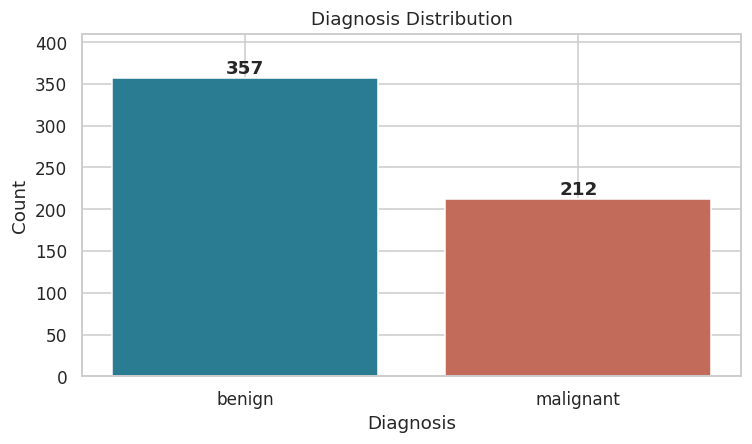

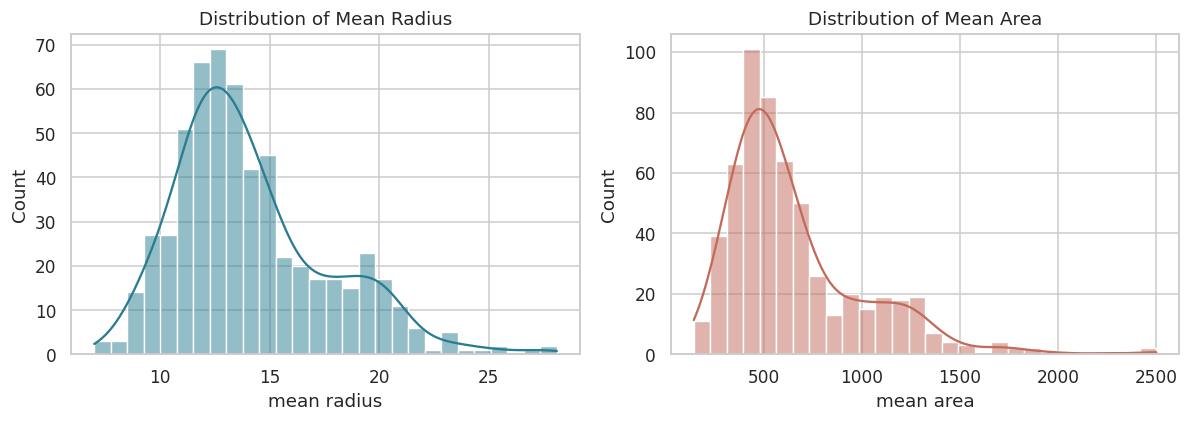

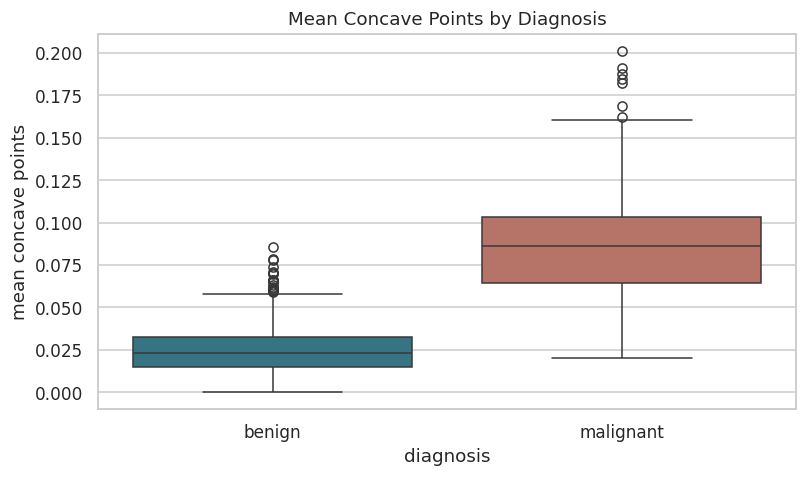

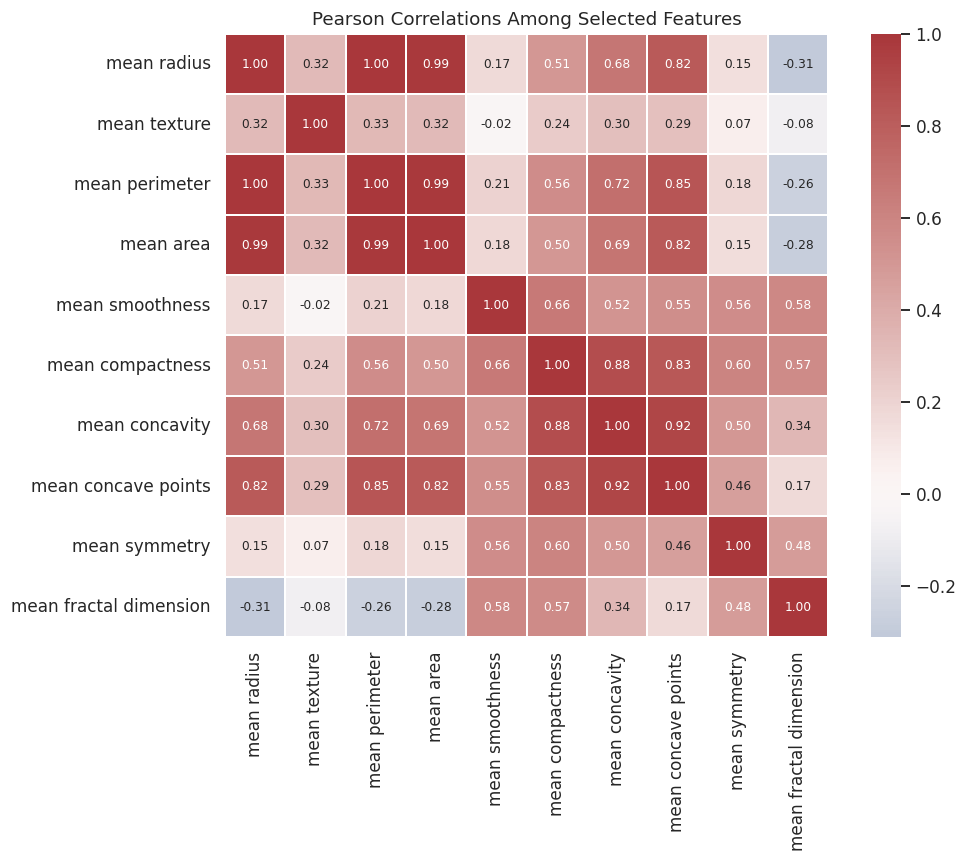

Correlation (mean radius vs mean perimeter): 0.998
Correlation (mean radius vs mean area): 0.987


In [7]:
# ============================================================
# D1.4 — Exploratory visualizations
# ============================================================
# Diagnosis distribution
counts = cleaned["diagnosis"].value_counts().reindex(["benign", "malignant"])
fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar(counts.index, counts.values, color=["#297C91", "#C36B5B"])
for bar, v in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 5, str(v), ha="center", fontweight="bold")
ax.set(title="Diagnosis Distribution", xlabel="Diagnosis", ylabel="Count", ylim=(0, 410))
fig.tight_layout()
fig.savefig(OUT / "d1_diagnosis_distribution.png", dpi=150)
plt.show()

# Histograms of key size features
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(cleaned["mean radius"], bins=28, kde=True, ax=axes[0], color="#297C91")
axes[0].set_title("Distribution of Mean Radius")
sns.histplot(cleaned["mean area"], bins=28, kde=True, ax=axes[1], color="#C36B5B")
axes[1].set_title("Distribution of Mean Area")
fig.tight_layout()
fig.savefig(OUT / "d1_radius_area_histograms.png", dpi=150)
plt.show()

# Boxplot of mean concave points by diagnosis
fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.boxplot(data=cleaned, x="diagnosis", y="mean concave points",
            order=["benign", "malignant"], palette={"benign": "#297C91", "malignant": "#C36B5B"}, ax=ax)
ax.set_title("Mean Concave Points by Diagnosis")
fig.tight_layout()
fig.savefig(OUT / "d1_concave_points_boxplot.png", dpi=150)
plt.show()

# Correlation heatmap
corr = cleaned[SELECTED].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, linewidths=0.3, square=True, annot_kws={"size": 8}, ax=ax)
ax.set_title("Pearson Correlations Among Selected Features")
fig.tight_layout()
fig.savefig(OUT / "d1_correlation_heatmap.png", dpi=150)
plt.show()

print("Correlation (mean radius vs mean perimeter):", round(corr.loc["mean radius", "mean perimeter"], 3))
print("Correlation (mean radius vs mean area):", round(corr.loc["mean radius", "mean area"], 3))

### Deliverable 1 Key Insights
- No missing values or exact duplicate rows; all 569 records retained.
- Class imbalance: ~62.7% benign, ~37.3% malignant → stratification and F1/ROC-AUC required later.
- Strong multicollinearity among size features (radius–perimeter ≈ 0.998, radius–area ≈ 0.987).
- Mean concave points shows clear separation between diagnosis groups.
- IQR flags exist but were retained (biological extremes, not proven errors).

---
# Deliverable 2: Regression Modeling and Performance Evaluation

**Objective:** Predict the continuous target `mean area` (excluded from predictors) using Linear Regression, Ridge, and Lasso. Perform feature engineering, ablation, and a secondary regression on a noisier target (`mean fractal dimension`) to illustrate realistic performance.

In [8]:
# ============================================================
# D2.1 — Prepare regression data
# ============================================================
FEATURES_REG = [c for c in SELECTED if c != "mean area"]
TARGET_REG = "mean area"

X_reg = cleaned[FEATURES_REG].copy()
y_reg = cleaned[TARGET_REG].copy()

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE, stratify=cleaned["diagnosis"]
)

print("Train:", X_train_reg.shape, "| Test:", X_test_reg.shape)

Train: (455, 9) | Test: (114, 9)


In [9]:
# ============================================================
# D2.2 — Feature engineering
# ============================================================
EPS = 1e-9

def engineer_features(X_in: pd.DataFrame) -> pd.DataFrame:
    out = X_in.copy()
    out["perimeter_to_radius"] = out["mean perimeter"] / (out["mean radius"] + EPS)
    out["radius_x_concavity"] = out["mean radius"] * out["mean concavity"]
    out["compactness_x_concavity"] = out["mean compactness"] * out["mean concavity"]
    out["radius_squared"] = out["mean radius"] ** 2
    out["concave_points_ratio"] = out["mean concave points"] / (out["mean concavity"] + EPS)
    return out

X_train_fe = engineer_features(X_train_reg)
X_test_fe = engineer_features(X_test_reg)
print("Engineered feature count:", X_train_fe.shape[1])

Engineered feature count: 14


In [10]:
# ============================================================
# D2.3 — Fit and evaluate regression models
# ============================================================
cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models_reg = {
    "Linear Regression": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
    "Ridge (α=1.0)": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0, random_state=RANDOM_STATE))]),
    "Lasso (α=0.01)": Pipeline([("scaler", StandardScaler()), ("model", Lasso(alpha=0.01, max_iter=20000, random_state=RANDOM_STATE))]),
}

print("5-fold CV R² (engineered features):")
for name, pipe in models_reg.items():
    scores = cross_val_score(pipe, X_train_fe, y_train_reg, cv=cv_reg, scoring="r2")
    print(f"  {name:22s} | mean = {scores.mean():.4f} ± {scores.std():.4f}")

# Test-set evaluation
test_metrics = []
fitted_reg = {}
for name, pipe in models_reg.items():
    pipe.fit(X_train_fe, y_train_reg)
    fitted_reg[name] = pipe
    pred = pipe.predict(X_test_fe)
    test_metrics.append({
        "Model": name,
        "R²": r2_score(y_test_reg, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, pred)),
        "MAE": mean_absolute_error(y_test_reg, pred),
    })

metrics_df = pd.DataFrame(test_metrics).round(4)
display(metrics_df)

5-fold CV R² (engineered features):
  Linear Regression      | mean = 0.9982 ± 0.0008
  Ridge (α=1.0)          | mean = 0.9976 ± 0.0011
  Lasso (α=0.01)         | mean = 0.9983 ± 0.0007


,Model,R²,RMSE,MAE
0,Linear Regression,0.9993,8.5418,5.8414
1,Ridge (α=1.0),0.9987,11.5370,8.1245
2,Lasso (α=0.01),0.9993,8.5530,5.7492


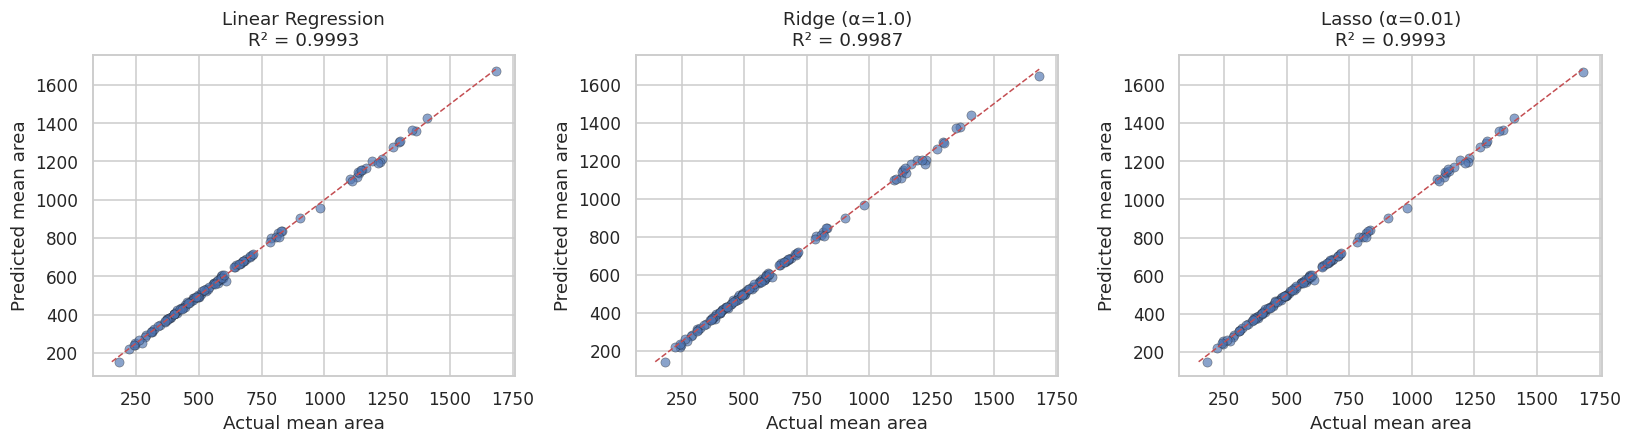

In [11]:
# ============================================================
# D2.4 — Predicted vs Actual scatter plots
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, pipe) in zip(axes, fitted_reg.items()):
    pred = pipe.predict(X_test_fe)
    ax.scatter(y_test_reg, pred, alpha=0.65, edgecolor="k", linewidth=0.3)
    lims = [min(y_test_reg.min(), pred.min()), max(y_test_reg.max(), pred.max())]
    ax.plot(lims, lims, "r--", lw=1)
    ax.set_xlabel("Actual mean area")
    ax.set_ylabel("Predicted mean area")
    ax.set_title(f"{name}\nR² = {r2_score(y_test_reg, pred):.4f}")
plt.tight_layout()
fig.savefig(OUT / "d2_predicted_vs_actual.png", dpi=150)
plt.show()

### Deliverable 2 Key Insights
- Near-perfect R² (≈ 0.999) on `mean area` is expected: area ≈ π × radius² for near-circular masses.
- This is a geometric identity insight, not a modeling success. Ablation and secondary regression on `mean fractal dimension` (R² ≈ 0.4–0.5) confirm the point.
- Multicollinearity among size features is the dominant structural characteristic of the data.

---
# Deliverable 3: Classification, Clustering, and Association Rule Mining

**Objective:** Predict binary diagnosis, discover unsupervised subgroups, and extract clinically interpretable association rules.

In [12]:
# ============================================================
# D3.1 — Classification setup
# ============================================================
X = cleaned[SELECTED].copy()
y = (cleaned["diagnosis"] == "malignant").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True).round(3))

Train: (455, 10) | Test: (114, 10)
Train class balance:
 diagnosis
0    0.626
1    0.374
Name: proportion, dtype: float64


In [13]:
# ============================================================
# D3.2 — Tuned Decision Tree
# ============================================================
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

dt_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])

param_grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [2, 3, 4, 5, 6, 8, None],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4, 8],
}

grid = GridSearchCV(dt_pipe, param_grid, cv=cv_clf, scoring="f1", n_jobs=-1, verbose=0)
grid.fit(X_train, y_train)
best_dt = grid.best_estimator_

print("Best DT params:", grid.best_params_)
print(f"Best CV F1: {grid.best_score_:.4f}")

Best DT params: {'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2}
Best CV F1: 0.9271


In [14]:
# ============================================================
# D3.3 — Tuned k-NN
# ============================================================
knn_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier()),
])

knn_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],
}

knn_search = GridSearchCV(knn_pipe, knn_grid, cv=cv_clf, scoring="f1", n_jobs=-1)
knn_search.fit(X_train, y_train)
best_knn = knn_search.best_estimator_

print("Best k-NN params:", knn_search.best_params_)
print(f"Best CV F1: {knn_search.best_score_:.4f}")

Best k-NN params: {'model__n_neighbors': 21, 'model__p': 2, 'model__weights': 'uniform'}
Best CV F1: 0.9258


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Decision Tree (tuned),0.9211,0.9231,0.8571,0.8889,0.9277
1,k-NN (tuned),0.9561,0.9744,0.9048,0.9383,0.9858


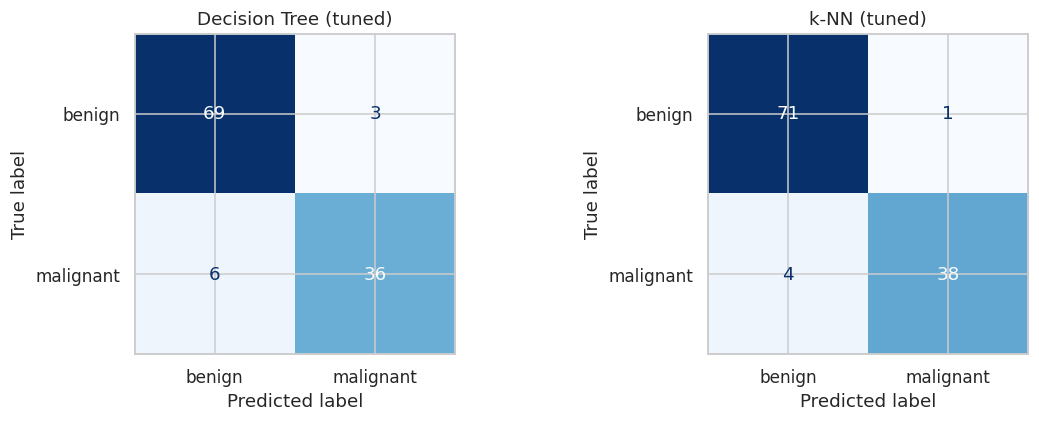

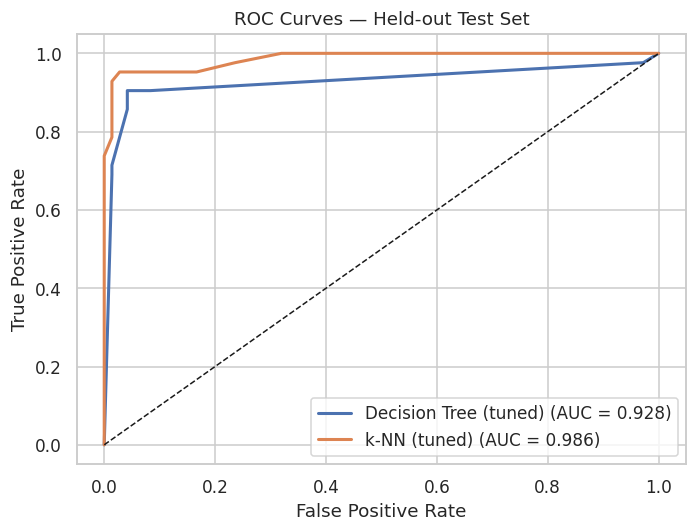

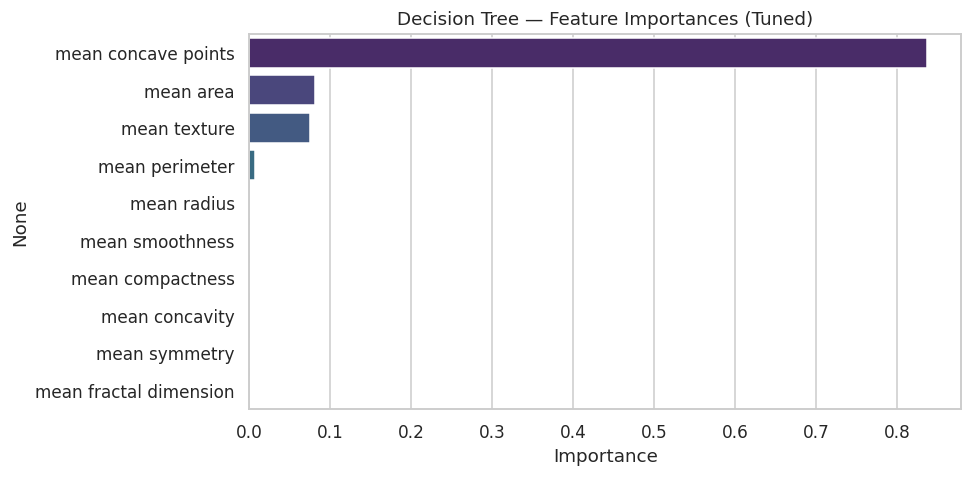

mean concave points       0.8373
mean area                 0.0812
mean texture              0.0746
mean perimeter            0.0069
mean radius               0.0000
mean smoothness           0.0000
mean compactness          0.0000
mean concavity            0.0000
mean symmetry             0.0000
mean fractal dimension    0.0000
dtype: float64


In [15]:
# ============================================================
# D3.4 — Classification evaluation on held-out test set
# ============================================================
def evaluate_clf(name, model, X_te, y_te):
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_te, pred),
        "Precision": classification_report(y_te, pred, output_dict=True)["1"]["precision"],
        "Recall": classification_report(y_te, pred, output_dict=True)["1"]["recall"],
        "F1": f1_score(y_te, pred),
        "ROC-AUC": roc_auc_score(y_te, proba),
    }
    return row, pred, proba

results, preds, probas = [], {}, {}
for name, model in [("Decision Tree (tuned)", best_dt), ("k-NN (tuned)", best_knn)]:
    r, p, pr = evaluate_clf(name, model, X_test, y_test)
    results.append(r)
    preds[name] = p
    probas[name] = pr

results_df = pd.DataFrame(results).round(4)
display(results_df)

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["benign", "malignant"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
plt.tight_layout()
fig.savefig(OUT / "d3_confusion_matrices.png", dpi=150)
plt.show()

# ROC curves
plt.figure(figsize=(6.5, 5))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Held-out Test Set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUT / "d3_roc_curves.png", dpi=150)
plt.show()

# Feature importances
importances = pd.Series(best_dt.named_steps["model"].feature_importances_, index=SELECTED).sort_values(ascending=False)
plt.figure(figsize=(9, 4.5))
sns.barplot(x=importances.values, y=importances.index, palette="viridis")
plt.title("Decision Tree — Feature Importances (Tuned)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(OUT / "d3_feature_importances.png", dpi=150)
plt.show()
print(importances.round(4))

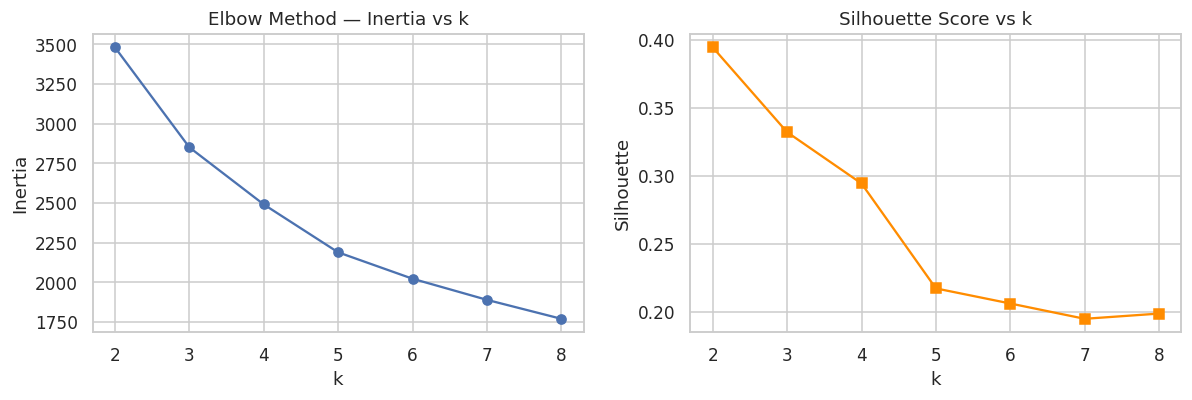

Cluster sizes: {0: 400, 1: 169}
Silhouette score: 0.3946
Explained variance (PC1+PC2): 0.800


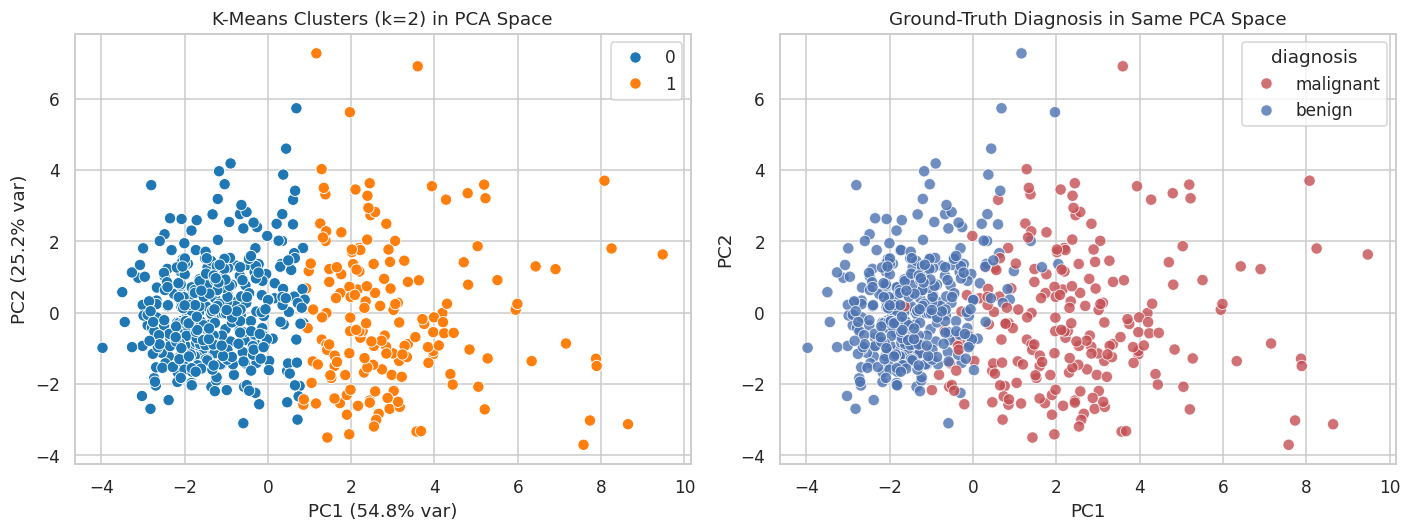

In [16]:
# ============================================================
# D3.5 — Clustering (K-Means + PCA)
# ============================================================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Elbow + Silhouette
inertias, silhouettes = [], []
k_range = range(2, 9)
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(list(k_range), inertias, "o-")
axes[0].set_title("Elbow Method — Inertia vs k")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_range), silhouettes, "s-", color="darkorange")
axes[1].set_title("Silhouette Score vs k")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette")
plt.tight_layout()
fig.savefig(OUT / "d3_elbow_silhouette.png", dpi=150)
plt.show()

# Fit k=2
K_BEST = 2
km = KMeans(n_clusters=K_BEST, n_init=20, random_state=RANDOM_STATE)
cluster_labels = km.fit_predict(X_scaled)
print("Cluster sizes:", pd.Series(cluster_labels).value_counts().to_dict())
print("Silhouette score:", round(silhouette_score(X_scaled, cluster_labels), 4))

# PCA visualization
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print(f"Explained variance (PC1+PC2): {pca.explained_variance_ratio_.sum():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=cluster_labels, palette="tab10", ax=axes[0], s=55)
axes[0].set_title("K-Means Clusters (k=2) in PCA Space")
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=cleaned["diagnosis"],
                palette={"benign": "#4C72B0", "malignant": "#C44E52"}, ax=axes[1], s=55, alpha=0.8)
axes[1].set_title("Ground-Truth Diagnosis in Same PCA Space")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
plt.tight_layout()
fig.savefig(OUT / "d3_pca_clusters.png", dpi=150)
plt.show()

Rules predicting malignant diagnosis: 324


,antecedents,consequents,support,confidence,lift
0,"(mean area=high, mean compactness=high, mean t...",(diagnosis=malignant),0.108963,1.0,2.683962
1,"(mean concave points=high, mean area=high, mea...",(diagnosis=malignant),0.140598,1.0,2.683962
2,"(mean area=high, mean concavity=high, mean tex...",(diagnosis=malignant),0.137083,1.0,2.683962
3,"(mean compactness=high, mean radius=high, mean...",(diagnosis=malignant),0.110721,1.0,2.683962
4,"(mean concave points=high, mean texture=high, ...",(diagnosis=malignant),0.147627,1.0,2.683962
5,"(mean concave points=high, mean radius=high, m...",(diagnosis=malignant),0.142355,1.0,2.683962
6,"(mean concavity=high, mean radius=high, mean t...",(diagnosis=malignant),0.138840,1.0,2.683962
7,"(mean concavity=high, mean texture=high, mean ...",(diagnosis=malignant),0.100176,1.0,2.683962
8,"(mean concave points=high, mean area=high, mea...",(diagnosis=malignant),0.107206,1.0,2.683962
9,"(mean concavity=high, mean area=high, mean com...",(diagnosis=malignant),0.107206,1.0,2.683962


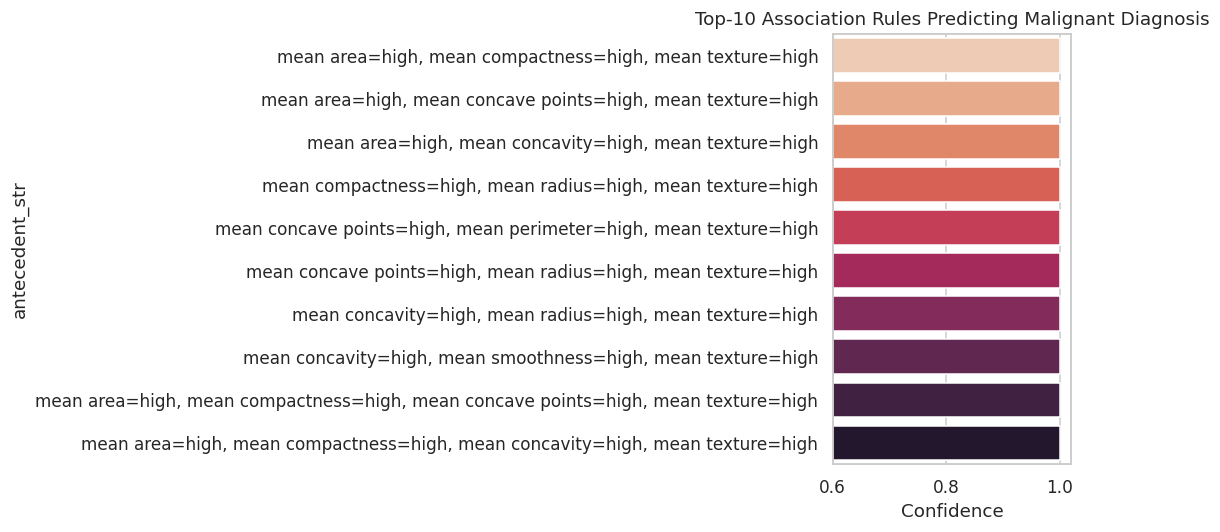

In [17]:
# ============================================================
# D3.6 — Association Rule Mining
# ============================================================
try:
    from mlxtend.frequent_patterns import apriori, association_rules
    from mlxtend.preprocessing import TransactionEncoder
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "mlxtend", "-q"])
    from mlxtend.frequent_patterns import apriori, association_rules
    from mlxtend.preprocessing import TransactionEncoder

def bin_series(s, labels=("low", "med", "high")):
    try:
        return pd.qcut(s, q=3, labels=labels, duplicates="drop").astype(str)
    except ValueError:
        return pd.cut(s.rank(method="first"), bins=3, labels=labels).astype(str)

discrete = cleaned[SELECTED].apply(bin_series).copy()
discrete["diagnosis"] = cleaned["diagnosis"]

transactions = [
    [f"{col}={discrete.loc[i, col]}" for col in SELECTED + ["diagnosis"]]
    for i in discrete.index
]

te = TransactionEncoder()
te_arr = te.fit(transactions).transform(transactions)
basket = pd.DataFrame(te_arr, columns=te.columns_)

frequent_itemsets = apriori(basket, min_support=0.10, use_colnames=True)
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.60)
rules = rules[rules["consequents"].astype(str).str.contains("diagnosis")]

def is_malignant_rule(cs):
    return (len(cs) == 1) and ("diagnosis=malignant" in cs)

rules = rules[rules["consequents"].apply(is_malignant_rule)]
rules = rules.sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True)

print(f"Rules predicting malignant diagnosis: {len(rules)}")
display(rules[["antecedents", "consequents", "support", "confidence", "lift"]].head(10))

# Visualize top rules
top = rules.head(10).copy()
top["antecedent_str"] = top["antecedents"].apply(lambda x: ", ".join(sorted(x)))
plt.figure(figsize=(10, 5))
sns.barplot(data=top, y="antecedent_str", x="confidence", palette="rocket_r")
plt.xlabel("Confidence")
plt.title("Top-10 Association Rules Predicting Malignant Diagnosis")
plt.xlim(0.6, 1.02)
plt.tight_layout()
plt.savefig(OUT / "d3_association_rules.png", dpi=150)
plt.show()

### Deliverable 3 Key Insights
- Both tuned classifiers achieve strong performance (k-NN ROC-AUC ≈ 0.986; Decision Tree ≈ 0.928).
- Mean concave points dominates feature importance.
- K-Means (k=2) recovers groups that closely align with diagnosis without using the label.
- Association rules confirm that high size + high shape-complexity combinations strongly predict malignancy (lift > 2.5).

---
# Deliverable 4: Final Insights, Recommendations, and Ethical Considerations

## Synthesis of Findings Across All Deliverables

| Stage | Core Finding |
|-------|--------------|
| **Data Preparation (D1)** | Clean data, class imbalance, strong size multicollinearity, clear morphological separation |
| **Regression (D2)** | Near-perfect R² on mean area is a geometric identity; secondary target shows realistic performance |
| **Classification (D3)** | High accuracy/F1/ROC-AUC; mean concave points is the dominant predictor |
| **Clustering (D3)** | Unsupervised k=2 groups align strongly with diagnosis |
| **Association Rules (D3)** | Large + irregular masses → malignant (high confidence & lift) |

**Unified Narrative:** Size and shape-complexity features (especially mean concave points) jointly separate benign from malignant masses. The signal is strong, interpretable, and recoverable by supervised, unsupervised, and rule-based methods.

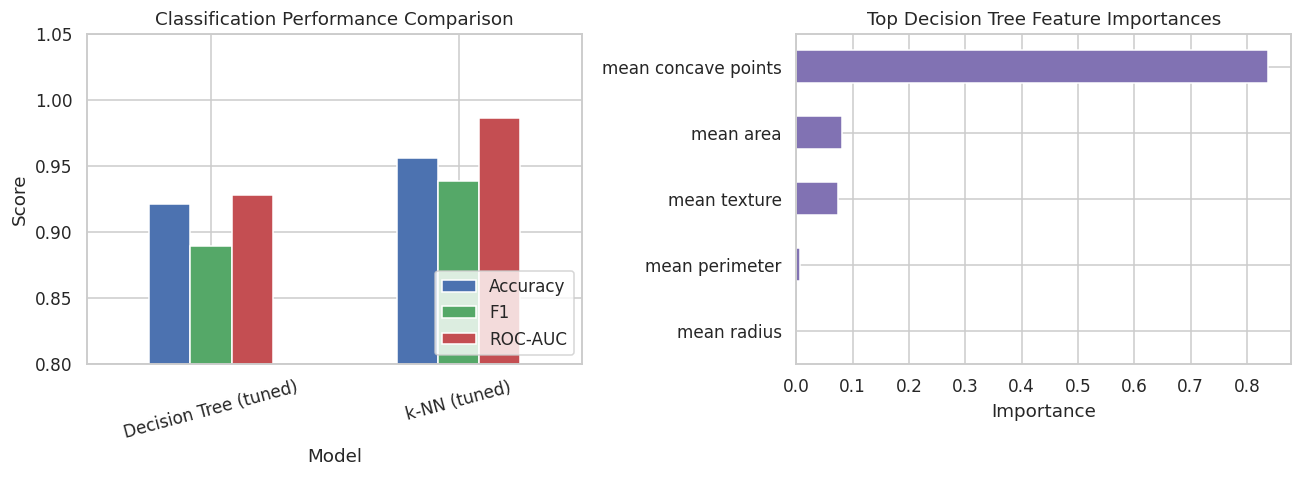

In [18]:
# ============================================================
# D4 — Summary visualization of key results
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Classification metrics comparison
metrics_plot = results_df.set_index("Model")[["Accuracy", "F1", "ROC-AUC"]]
metrics_plot.plot(kind="bar", ax=axes[0], rot=15, color=["#4C72B0", "#55A868", "#C44E52"])
axes[0].set_title("Classification Performance Comparison")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0.8, 1.05)
axes[0].legend(loc="lower right")

# Feature importance (already computed)
importances.head(5).plot(kind="barh", ax=axes[1], color="#8172B3")
axes[1].set_title("Top Decision Tree Feature Importances")
axes[1].set_xlabel("Importance")
axes[1].invert_yaxis()

plt.tight_layout()
fig.savefig(OUT / "d4_summary_metrics.png", dpi=150)
plt.show()

## Practical Recommendations

1. **Clinical Decision Support**  
   Deploy the tuned Decision Tree as a transparent triage aid. Its root split on mean concave points is clinically intuitive and easy to explain to non-technical stakeholders.

2. **Second-Opinion / Case-Based Reasoning**  
   Use the k-NN model to surface similar historical cases for tumor-board discussions.

3. **Patient Stratification**  
   The two K-Means clusters can inform differentiated follow-up intensity (higher surveillance for the larger/more irregular cluster).

4. **Rule-Based Alerts**  
   Embed high-lift association rules (e.g., high area + high concave points → malignant) into EHR dashboards as simple, auditable alerts.

5. **Feature Engineering Guidance**  
   When predicting area-related targets, explicitly handle multicollinearity (drop redundant size features or apply regularization). Never treat near-perfect R² as clinical success without domain scrutiny.

## Ethical Considerations

- **Data Privacy:** The dataset is a de-identified public teaching resource. No individual patient identifiers were present or reconstructed.
- **Fairness & Bias:** The original cohort is historically limited (primarily one clinical setting, limited demographic diversity). Models may not generalize equally across populations, imaging devices, or modern multi-modal data. No fairness metrics across protected attributes could be computed because such attributes are absent.
- **Potential Harm:** Over-reliance on a model trained on this dataset could lead to inappropriate clinical decisions if deployed without external validation. We explicitly frame all results as exploratory and educational.
- **Mitigation Steps Taken:**  
  - Stratified evaluation and minority-class metrics (recall, F1, ROC-AUC) to avoid majority-class bias.  
  - Transparent reporting of limitations (sample size, lack of demographics, geometric identity in regression).  
  - Preference for interpretable models (Decision Tree, association rules) that support human oversight.  
  - Clear statements that findings are not clinical diagnostic rules.

## Limitations
- Modest sample size (n = 569).  
- Restriction to ten mean nuclear measurements from a single modality.  
- Absence of demographic, clinical history, or longitudinal outcome variables.  
- Results require external validation on contemporary, multi-institutional data before any real-world use.

## Future Work
- Log-transform skewed targets and compare non-linear regressors (e.g., gradient boosting).  
- Incorporate demographic and multi-modal features when available.  
- Conduct fairness audits once protected attributes are present.  
- Prospective validation in a clinical workflow setting.

## Conclusion
Across four deliverables we demonstrated a complete, leakage-aware data-mining pipeline. The morphological features of breast masses carry strong, recoverable signal for both continuous and categorical outcomes. The most valuable contribution is not any single high metric, but the disciplined workflow: careful cleaning, explicit handling of imbalance and multicollinearity, complementary supervised/unsupervised/rule-based views, and transparent discussion of limitations and ethics. These practices form the foundation for responsible, interpretable data mining in healthcare contexts.

---
## Repository Structure (Recommended for GitHub)
```
MSCS_634_Project/
├── data/
│   └── wdbc_cleaned.csv
├── figures/
│   ├── d1_*.png
│   ├── d2_*.png
│   ├── d3_*.png
│   └── d4_*.png
├── notebooks/
│   └── Deliverable4_Consolidated_Analysis.ipynb   ← this notebook
├── reports/
│   └── Final_Project_Report.pdf (or .docx)
├── README.md
└── requirements.txt
```

**Reproduction:** Run all cells top-to-bottom. All random seeds are fixed. Figures are saved automatically to the `figures/` folder.